In [1]:
#load anndata

import scanpy as sc


anndata= sc.read_h5ad("../data/raw/MTG_snRNAseq.h5ad", backed="r")


/export/space3/users/rafadiaz/conda_envs/neuronet/lib/python3.12/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/export/space3/users/rafadiaz/conda_envs/neuronet/lib/python3.12/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/export/space3/users/rafadiaz/conda_envs/neuronet/lib/python3.12/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


In [2]:
anndata.obs.columns.to_list()

['assay_ontology_term_id',
 'cell_type_ontology_term_id',
 'disease_ontology_term_id',
 'self_reported_ethnicity_ontology_term_id',
 'sex_ontology_term_id',
 'tissue_ontology_term_id',
 'is_primary_data',
 'Neurotypical reference',
 'Class',
 'Subclass',
 'Supertype',
 'Age at death',
 'Years of education',
 'Cognitive status',
 'ADNC',
 'Braak stage',
 'Thal phase',
 'CERAD score',
 'APOE4 status',
 'Lewy body disease pathology',
 'LATE-NC stage',
 'Microinfarct pathology',
 'Specimen ID',
 'donor_id',
 'PMI',
 'Number of UMIs',
 'Genes detected',
 'Fraction mitochrondrial UMIs',
 'suspension_type',
 'development_stage_ontology_term_id',
 'Continuous Pseudo-progression Score',
 'tissue_type',
 'cell_type',
 'assay',
 'disease',
 'sex',
 'tissue',
 'self_reported_ethnicity',
 'development_stage',
 'observation_joinid']

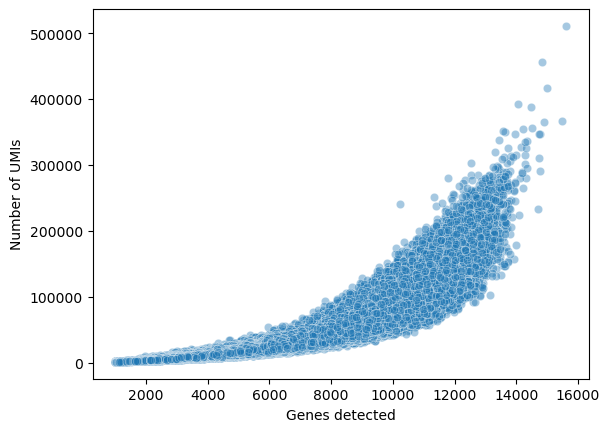

Spearman rho = 0.982


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

df_umis_genes = anndata.obs[["Subclass", "ADNC", "Number of UMIs", "Genes detected"]].copy()

sns.scatterplot(data=df_umis_genes, x="Genes detected", y="Number of UMIs", alpha=0.4)
plt.xlabel("Genes detected")
plt.ylabel("Number of UMIs")
plt.show()

rho = df_umis_genes["Genes detected"].corr(df_umis_genes["Number of UMIs"], method="spearman")
print(f"Spearman rho = {rho:.3f}")

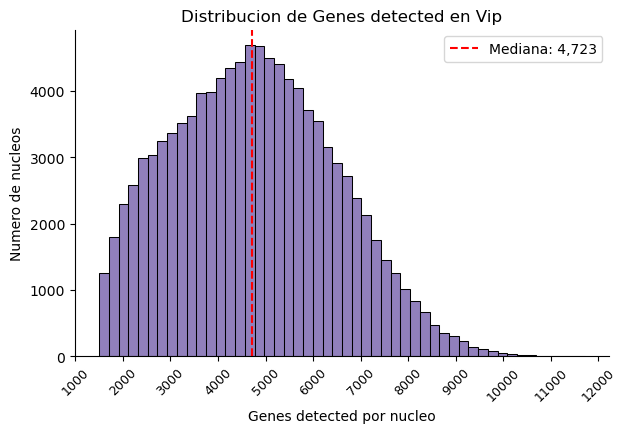

In [3]:


#plot umi distribution by subclass
import matplotlib.pyplot as plt
import seaborn as sns

df_umis = anndata.obs[["Subclass", 'Genes detected']].copy()

umis_by_subclass = (
    df_umis.groupby("Subclass", observed=True)["Genes detected"]
    .apply(list)
)

g = sns.displot(
    data=df_umis[df_umis["Subclass"] == "Vip"],
    x="Genes detected",
    bins=50,
    color="#6D55A6",
    height=4,
    aspect=1.6
)

g.ax.locator_params(axis="x", nbins=18)
g.ax.tick_params(axis="x", labelrotation=45)
g.ax.tick_params(axis="x", labelsize=9)
g.ax.set_title("Distribucion de Genes detected en Vip")
g.set_axis_labels("Genes detected por nucleo", "Numero de nucleos")

median = df_umis.loc[
    df_umis["Subclass"] == "Vip", "Genes detected"
].median()

g.ax.axvline(
    median, color="red", linestyle="--",
    label=f"Mediana: {median:,.0f}"
)
g.ax.legend()

plt.show()

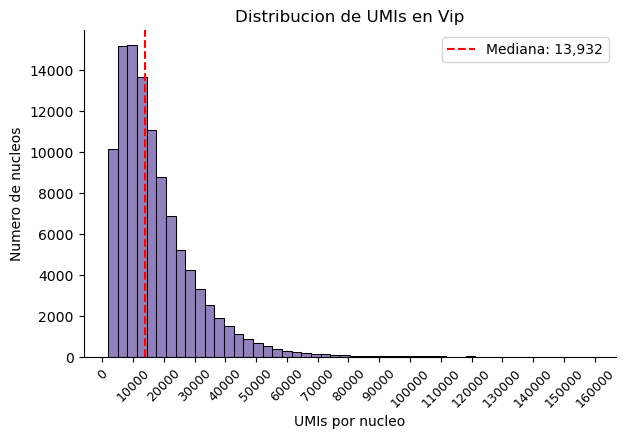

In [5]:
#plot umi distribution by subclass
import matplotlib.pyplot as plt
import seaborn as sns

df_umis = anndata.obs[["Subclass", "Number of UMIs"]].copy()

umis_by_subclass = (
    df_umis.groupby("Subclass", observed=True)["Number of UMIs"]
    .apply(list)
)

g = sns.displot(
    data=df_umis[df_umis["Subclass"] == "Vip"],
    x="Number of UMIs",
    bins=50,
    color="#6D55A6",
    height=4,
    aspect=1.6
)

g.ax.locator_params(axis="x", nbins=18)
g.ax.tick_params(axis="x", labelrotation=45)
g.ax.tick_params(axis="x", labelsize=9)
g.ax.set_title("Distribucion de UMIs en Vip")
g.set_axis_labels("UMIs por nucleo", "Numero de nucleos")

median = df_umis.loc[
    df_umis["Subclass"] == "Vip", "Number of UMIs"
].median()

g.ax.axvline(
    median, color="red", linestyle="--",
    label=f"Mediana: {median:,.0f}"
)
g.ax.legend()

plt.show()



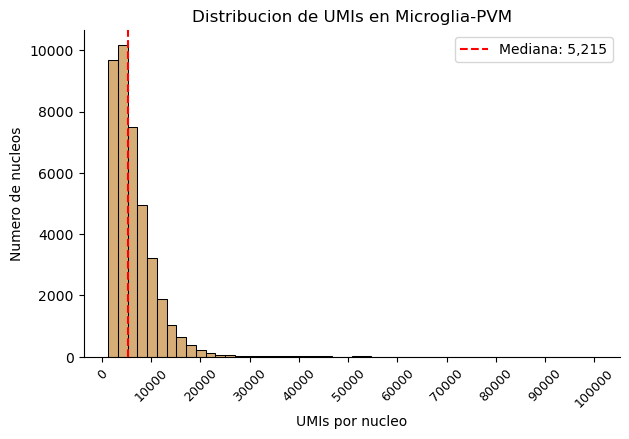

Subclass
Lamp5 Lhx6         [12857, 10022, 13167, 2465, 74180, 11709, 1664...
Lamp5              [9823, 11715, 27232, 24816, 12676, 7134, 7432,...
Pax6               [29504, 13291, 21078, 10482, 3621, 8207, 7454,...
Sncg               [6262, 5583, 8519, 9766, 4520, 15663, 27104, 1...
Vip                [4398, 19541, 8573, 29525, 16191, 5082, 7557, ...
Sst Chodl          [6430, 16528, 9559, 10783, 18764, 16582, 33046...
Sst                [18631, 10465, 8055, 13686, 4923, 6366, 6541, ...
Pvalb              [11358, 25571, 36801, 26428, 23210, 20814, 289...
Chandelier         [31267, 19505, 9507, 21189, 28037, 5747, 4603,...
L2/3 IT            [38523, 35622, 49393, 15844, 23314, 42240, 178...
L6 IT              [43847, 119065, 103084, 115412, 35427, 74409, ...
L4 IT              [17933, 51837, 25889, 8419, 78722, 16869, 2879...
L5 IT              [28718, 25386, 20242, 47905, 54632, 18378, 485...
L5 ET              [34431, 29638, 69474, 79077, 106940, 33845, 22...
L6 CT              [42252

In [4]:
g = sns.displot(
    data=df_umis[df_umis["Subclass"] == "Microglia-PVM"],
    x="Number of UMIs",
    bins=50,
    color="#C99149",
    height=4,
    aspect=1.6
)

g.ax.locator_params(axis="x", nbins=18)
g.ax.set_title("Distribucion de UMIs en Microglia-PVM")
g.set_axis_labels("UMIs por nucleo", "Numero de nucleos")
g.ax.tick_params(axis="x", labelrotation=45)
g.ax.tick_params(axis="x", labelsize=9)

median = df_umis.loc[
    df_umis["Subclass"] == "Microglia-PVM", "Number of UMIs"
].median()

g.ax.axvline(
    median, color="red", linestyle="--",
    label=f"Mediana: {median:,.0f}"
)
g.ax.legend()

plt.show()

umis_by_subclass

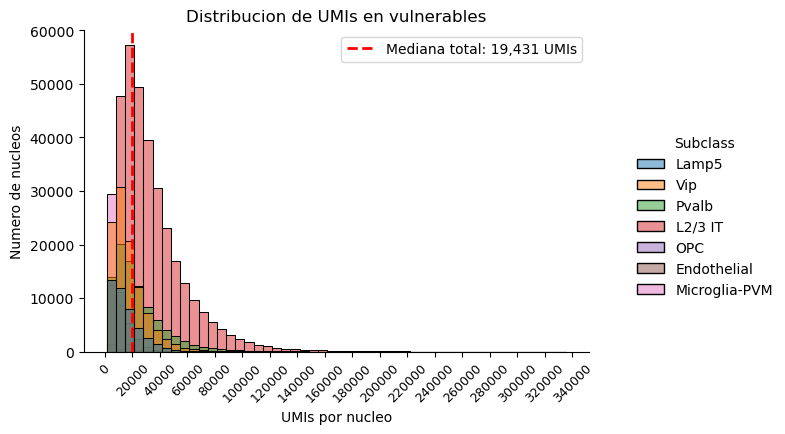

In [7]:

subclasses = [
    "Vip",
    "Microglia-PVM",
    "Astrocytes",
    "Oligodendrocytes",
    "OPC",
    "Endothelial",
    "Pvalb",
    "L2/3 IT",
    "Lamp5"
]

sub_df_umis = df_umis.loc[
    df_umis["Subclass"].isin(subclasses)
].copy()

sub_df_umis["Subclass"] = (
    sub_df_umis["Subclass"].cat.remove_unused_categories()
)

g = sns.displot(
    data=sub_df_umis,
    x="Number of UMIs",
    bins=50,
    hue="Subclass",
    height=4,
    aspect=1.6
)

g.ax.locator_params(axis="x", nbins=20)
g.ax.set_title("Distribucion de UMIs en vulnerables")
g.set_axis_labels("UMIs por nucleo", "Numero de nucleos")
g.ax.tick_params(axis="x", labelrotation=45)
g.ax.tick_params(axis="x", labelsize=9)

median = sub_df_umis["Number of UMIs"].median()

g.ax.axvline(
    median,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mediana total: {median:,.0f} UMIs"
)
g.ax.legend()

plt.show()

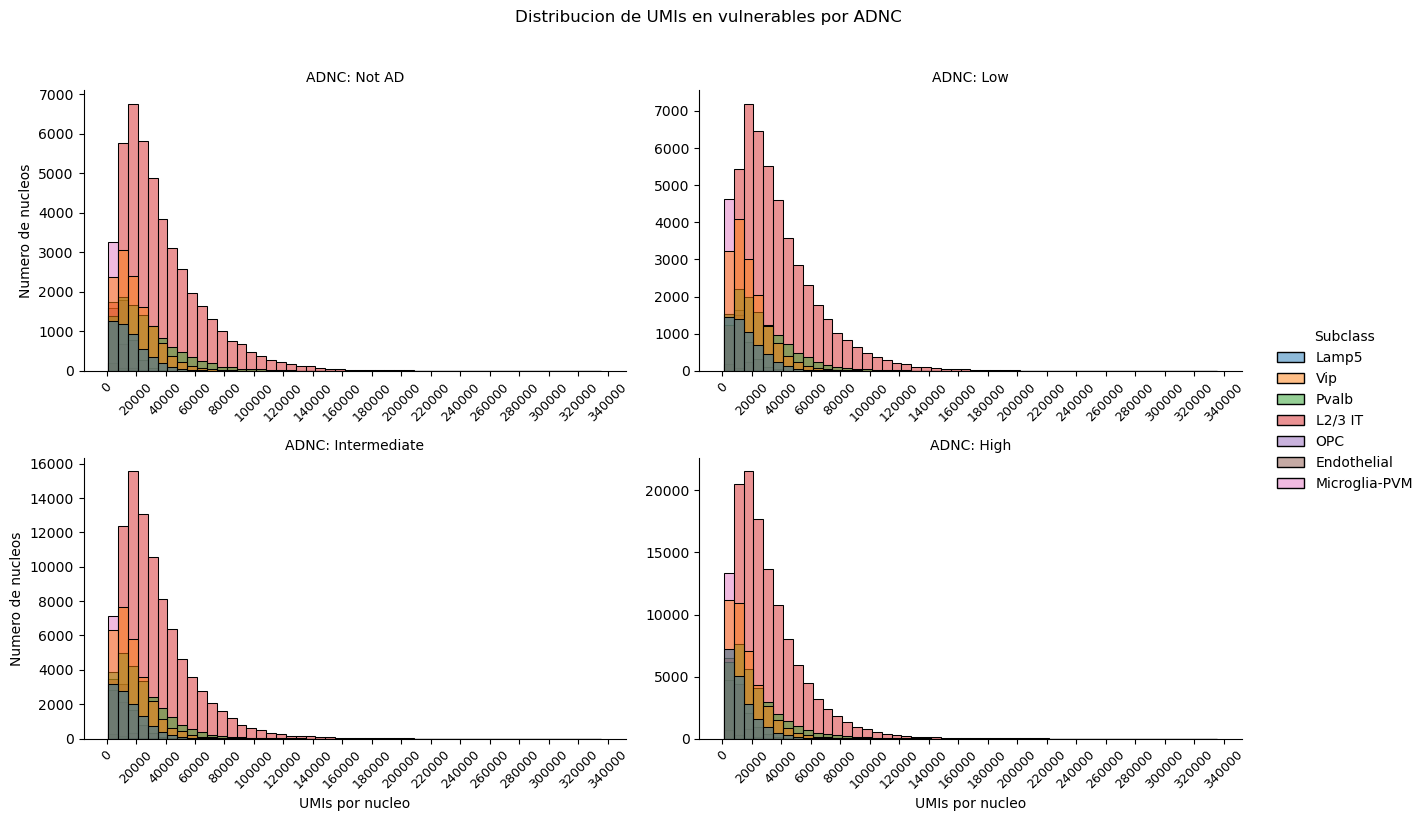

In [ ]:
import pandas as pd

df_umis = anndata.obs[["Subclass", "ADNC", "Number of UMIs"]].copy()
subclasses = [
    "Vip",
    "Microglia-PVM",
    "Astrocytes",
    "Oligodendrocytes",
    "OPC",
    "Endothelial",
    "Pvalb",
    "L2/3 IT",
    "Lamp5"
]
adnc_order = ["Not AD", "Low", "Intermediate", "High"]

sub_df_umis = df_umis.loc[
    df_umis["Subclass"].isin(subclasses)
    & df_umis["ADNC"].isin(adnc_order)
].copy()

sub_df_umis["Subclass"] = (
    sub_df_umis["Subclass"].cat.remove_unused_categories()
)


sub_df_umis["ADNC"] = pd.Categorical(
    sub_df_umis["ADNC"], categories=adnc_order, ordered=True
)

g = sns.displot(
    data=sub_df_umis,
    x="Number of UMIs",
    bins=50,
    hue="Subclass",
    col="ADNC",
    col_order=adnc_order,
    col_wrap=2,
    height=4,
    aspect=1.6,
    facet_kws={"sharey": False}
)

g.set_titles("ADNC: {col_name}")
g.set_axis_labels("UMIs por nucleo", "Numero de nucleos")
for ax in g.axes.flat:
    ax.locator_params(axis="x", nbins=20)
    ax.tick_params(axis="x", labelrotation=45, labelsize=9, labelbottom=True)

g.fig.suptitle("Distribucion de UMIs en vulnerables por ADNC", y=1.02)
g.tight_layout()

plt.show()

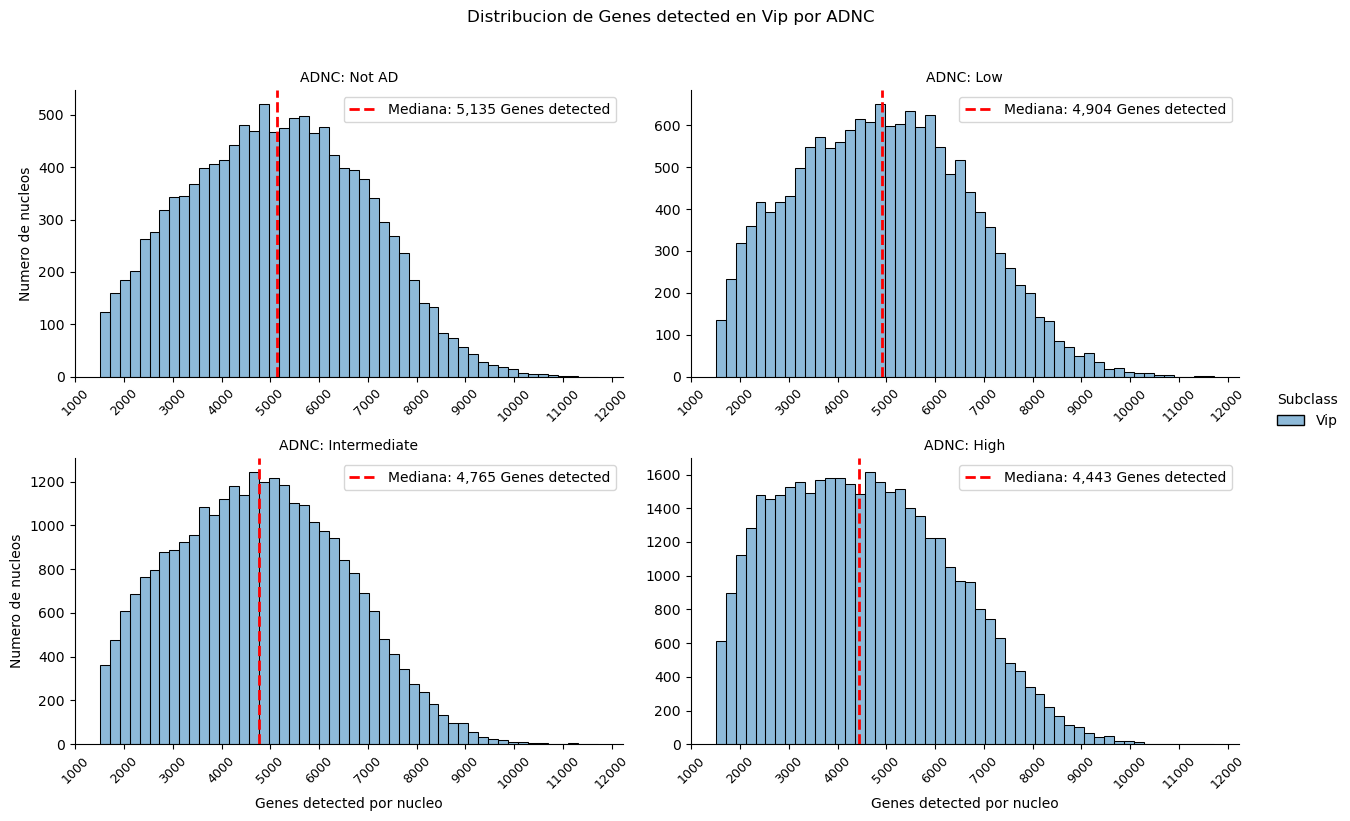

In [ ]:
import pandas as pd

df_micro = anndata.obs[["Subclass", "ADNC", "Number of UMIs"]].copy()
subclasses = [
    "Vip"
]
adnc_order = ["Not AD", "Low", "Intermediate", "High"]

sub_df_umis = df_micro.loc[
    df_micro["Subclass"].isin(subclasses)
    & df_micro["ADNC"].isin(adnc_order)
].copy()

sub_df_umis["Subclass"] = (
    sub_df_umis["Subclass"].cat.remove_unused_categories()
)


sub_df_umis["ADNC"] = pd.Categorical(
    sub_df_umis["ADNC"], categories=adnc_order, ordered=True
)

g = sns.displot(
    data=sub_df_umis,
    color="#C99149",
    x="Number of UMIs",
    bins=50,
    hue="Subclass",
    col="ADNC",
    col_order=adnc_order,
    col_wrap=2,
    height=4,
    aspect=1.6,
    facet_kws={"sharey": False}
)

g.set_titles("ADNC: {col_name}")
g.set_axis_labels("UMIs por nucleo", "Numero de nucleos")
for ax in g.axes.flat:
    ax.locator_params(axis="x", nbins=20)
    ax.tick_params(axis="x", labelrotation=45, labelsize=9, labelbottom=True)

g.fig.suptitle("Distribucion de UMIs en Vip por ADNC", y=1.02)
g.tight_layout()

median = sub_df_umis["Number of UMIs"].median()

medianas = sub_df_umis.groupby("ADNC", observed=True)["Number of UMIs"].median()

for ax, estadio in zip(g.axes.flat, adnc_order):
    mediana = medianas[estadio]
    ax.axvline(
        mediana,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mediana: {mediana:,.0f} UMIs"
    )
    ax.legend()

plt.show()

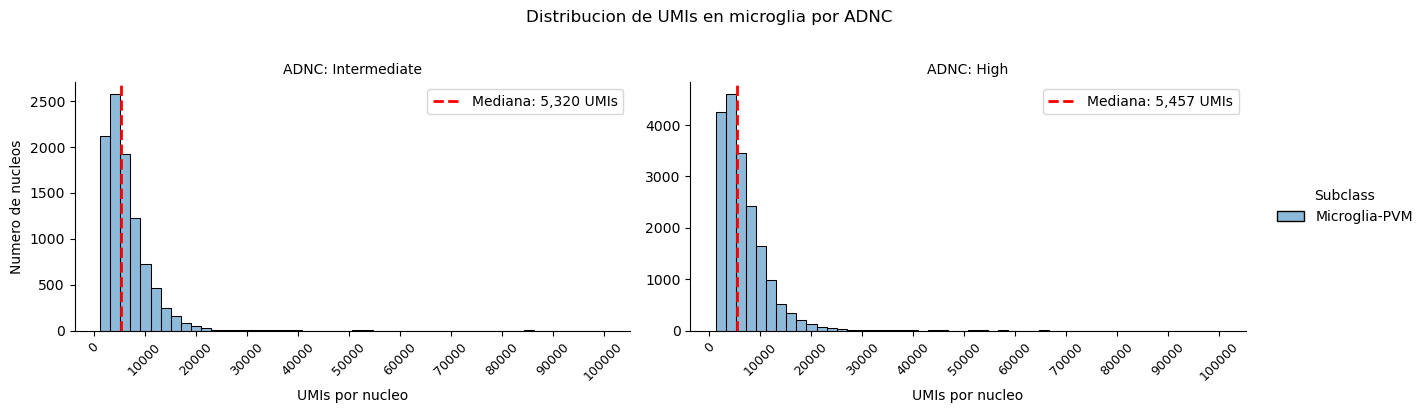

In [11]:
import pandas as pd

df_micro = anndata.obs[["Subclass", "ADNC", "Number of UMIs"]].copy()
subclasses = [
    "Microglia-PVM"
]
adnc_order = ["Intermediate", "High"]

sub_df_umis = df_micro.loc[
    df_micro["Subclass"].isin(subclasses)
    & df_micro["ADNC"].isin(adnc_order)
].copy()

sub_df_umis["Subclass"] = (
    sub_df_umis["Subclass"].cat.remove_unused_categories()
)


sub_df_umis["ADNC"] = pd.Categorical(
    sub_df_umis["ADNC"], categories=adnc_order, ordered=True
)

g = sns.displot(
    data=sub_df_umis,
    color="#C99149",
    x="Number of UMIs",
    bins=50,
    hue="Subclass",
    col="ADNC",
    col_order=adnc_order,
    col_wrap=2,
    height=4,
    aspect=1.6,
    facet_kws={"sharey": False}
)

g.set_titles("ADNC: {col_name}")
g.set_axis_labels("UMIs por nucleo", "Numero de nucleos")
for ax in g.axes.flat:
    ax.locator_params(axis="x", nbins=20)
    ax.tick_params(axis="x", labelrotation=45, labelsize=9, labelbottom=True)

g.fig.suptitle("Distribucion de UMIs en microglia por ADNC", y=1.02)
g.tight_layout()

median = sub_df_umis["Number of UMIs"].median()

medianas = sub_df_umis.groupby("ADNC", observed=True)["Number of UMIs"].median()

for ax, estadio in zip(g.axes.flat, adnc_order):
    mediana = medianas[estadio]
    ax.axvline(
        mediana,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mediana: {mediana:,.0f} UMIs"
    )
    ax.legend()

plt.show()